# 02 - Modelling
We train two kinds of model:
- **history model**: uses recent ridership (lags and rolling means). Most accurate, but needs recent data.
- **planning model**: uses only things known in advance (route, calendar, schedule, weather). This is the one the app will use.

Plan: split by time -> baselines -> 4 algorithms inside a Pipeline -> tune with 5-fold time-series CV -> pick on validation -> test once.

In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/transit_dataset.csv", parse_dates=["transit_timestamp"])
df = df.sort_values(["transit_timestamp", "bus_route"]).reset_index(drop=True)

## 1. Time-ordered split (70 / 15 / 15)
We split by **whole days**, oldest to newest. Shuffling would let the model see the future while predicting the past. All routes of the same hour always land in the same split.

In [2]:
day = df["transit_timestamp"].dt.normalize()
all_days = np.sort(day.unique())
a, b = int(len(all_days) * 0.70), int(len(all_days) * 0.85)

train = df[day.isin(all_days[:a])]
val = df[day.isin(all_days[a:b])]
test = df[day.isin(all_days[b:])]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(name, len(part), "rows,", part["transit_timestamp"].min().date(), "to", part["transit_timestamp"].max().date())

train 14976 rows, 2025-01-13 to 2025-07-17
val 3072 rows, 2025-07-18 to 2025-09-19
test 3456 rows, 2025-09-20 to 2025-09-28


## 2. Features
Dropped from the model inputs:
- `transit_timestamp`, `window_id`: identifiers, not real features.
- `month`: only 4 months exist, so it acts as a window label.
- `gtfs_n_directions`: equals 2 for every route.

In [3]:
history_cols = ["lag_1h", "lag_24h", "lag_168h", "roll_24h_mean", "roll_168h_mean"]
not_inputs = ["transit_timestamp", "window_id", "month", "gtfs_n_directions", "ridership"]
category_cols = ["bus_route", "borough"]

planning_features = [c for c in df.columns if c not in not_inputs + history_cols]
history_features = planning_features + history_cols
variants = {"planning": planning_features, "history": history_features}
target = "ridership"
print(len(planning_features), "planning features,", len(history_features), "history features")

26 planning features, 31 history features


## 3. Metrics and baselines
- **MAE**: average error in riders (our main metric, easy to explain to planners).
- **RMSE**: like MAE but punishes big misses more.
- **R2**: share of the variation explained (1 is perfect, 0 is no better than guessing the average).

Baselines (a model must beat these to be worth anything):
- *history baseline*: ridership at the same hour one week ago (`lag_168h`).
- *planning baseline*: the training average for that route, hour and weekday/weekend.

In [4]:
def scores(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

keys = ["bus_route", "hour", "is_weekend"]
typical = train.groupby(keys)["ridership"].mean().rename("typical").reset_index()

def planning_baseline(part):
    merged = part[keys].merge(typical, on=keys, how="left")
    return merged["typical"].fillna(train["ridership"].mean()).to_numpy()

def history_baseline(part):
    return part["lag_168h"].to_numpy()

rows = []
for name, part in [("train", train), ("val", val)]:
    rows.append({"baseline": "planning (route-hour average)", "split": name, **scores(part[target], planning_baseline(part))})
    rows.append({"baseline": "history (same hour last week)", "split": name, **scores(part[target], history_baseline(part))})
pd.DataFrame(rows).round(2)

,baseline,split,MAE,RMSE,R2
0,planning (route-hour average),train,66.73,111.35,0.93
1,history (same hour last week),train,65.48,123.99,0.92
2,planning (route-hour average),val,82.59,133.29,0.92
3,history (same hour last week),val,45.30,68.41,0.98


**Reading the baselines:** on validation, last week's value (MAE 45) is a much stronger guess than the route-hour average (MAE 83), because bus ridership repeats weekly. So the history models must beat 45 and the planning models must beat 83.

Test scores for the baselines are saved for the final step, so the test set is only looked at once.

## 4. Pipelines and the four algorithms
Each model sits in a scikit-learn `Pipeline`: preprocessing then model. The pipeline is fitted on training data only, so nothing from validation or test leaks into scaling or encoding.

- `bus_route` and `borough` are text, so they are **one-hot encoded** (`handle_unknown="ignore"` lets the app accept a route it never saw).
- Linear Regression and KNN need **scaled** numbers (KNN measures distances, so big columns like pressure would dominate). Tree models do not need scaling.

In [5]:
def make_pipeline(model, features, scale):
    cat = [c for c in features if c in category_cols]
    num = [c for c in features if c not in category_cols]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", StandardScaler() if scale else "passthrough", num),
    ])
    return Pipeline([("prep", prep), ("model", model)])

models = {
    "Linear Regression": (LinearRegression(), True, {}),
    "KNN": (KNeighborsRegressor(), True, {
        "model__n_neighbors": [5, 10, 20, 40],
        "model__weights": ["uniform", "distance"],
    }),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), False, {
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 5],
    }),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=42), False, {
        "model__n_estimators": [200, 400],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [3, 5],
    }),
}

## 5. Tuning with 5-fold time-series cross-validation
`TimeSeriesSplit` makes every fold train on the past and validate on the next chunk of time. Normal shuffled K-fold would train on future days to predict past days, which gives fake-good scores.

Grid search tries every setting in the grids above and keeps the one with the lowest CV MAE. Linear Regression has no settings to tune, so its grid is empty.

In [6]:
cv = TimeSeriesSplit(n_splits=5)
searches = {}
rows = []

for variant, features in variants.items():
    for name, (model, scale, grid) in models.items():
        pipe = make_pipeline(model, features, scale)
        search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
        search.fit(train[features], train[target])
        searches[(variant, name)] = search

        val_scores = scores(val[target], search.predict(val[features]))
        rows.append({
            "variant": variant, "model": name,
            "train MAE": mean_absolute_error(train[target], search.predict(train[features])),
            "CV MAE": -search.best_score_,
            "val MAE": val_scores["MAE"], "val RMSE": val_scores["RMSE"], "val R2": val_scores["R2"],
            "best params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        })
        print(variant, name, "done")

val_table = pd.DataFrame(rows)
val_table.drop(columns="best params").round(2)

planning Linear Regression done


planning KNN done


planning Random Forest done


planning Gradient Boosting done
history Linear Regression done


history KNN done


history Random Forest done


history Gradient Boosting done


,variant,model,train MAE,CV MAE,val MAE,val RMSE,val R2
0,planning,Linear Regression,129.37,147.11,141.94,201.46,0.81
1,planning,KNN,0.00,135.37,99.18,155.31,0.88
2,planning,Random Forest,15.61,80.44,74.87,133.64,0.91
3,planning,Gradient Boosting,44.84,80.96,76.49,122.65,0.93
4,history,Linear Regression,56.93,76.05,61.58,84.80,0.97
5,history,KNN,0.00,98.93,73.26,110.01,0.94
6,history,Random Forest,14.43,60.48,40.80,64.04,0.98
7,history,Gradient Boosting,31.69,60.23,44.45,67.48,0.98


**Reading the validation table:**
- **Random Forest** has the lowest validation MAE in both variants (planning 74.9, history 40.8). Gradient Boosting is close behind (76.5 and 44.4).
- **KNN has a train MAE of 0.0.** With `weights="distance"`, the nearest neighbour of a training row is the row itself, so KNN just memorises the training data. That number is not a real score. Its validation error is much higher, which is **over-fitting**.
- **Linear Regression is worst in the planning variant** (val MAE 142). It can only draw straight lines, but ridership over the day is a double hump. This is **under-fitting**. With history features it does fine (61.6) because `lag_168h` alone is almost the answer.
- Some best settings sit at the edge of our grid (Gradient Boosting planning: learning rate 0.05 and depth 5; Random Forest history: no depth limit). A wider grid might help slightly; we kept the grids small to keep run time reasonable.

In [7]:
val_table[["variant", "model", "best params"]]

,variant,model,best params
0,planning,Linear Regression,{}
1,planning,KNN,"{'n_neighbors': 5, 'weights': 'distance'}"
2,planning,Random Forest,"{'max_depth': 20, 'min_samples_leaf': 1}"
3,planning,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est..."
4,history,Linear Regression,{}
5,history,KNN,"{'n_neighbors': 10, 'weights': 'distance'}"
6,history,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1}"
7,history,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est..."


**Reading the validation table:**
- **Random Forest** has the lowest validation MAE in both variants (planning 74.9, history 40.8). Gradient Boosting is close behind (76.5 and 44.4).
- **KNN has a train MAE of 0.0.** With `weights="distance"`, the nearest neighbour of a training row is the row itself, so KNN just memorises the training data. That number is not a real score. Its validation error is much higher, which is **over-fitting**.
- **Linear Regression is worst in the planning variant** (val MAE 142). It can only draw straight lines, but ridership over the day is a double hump. This is **under-fitting**. With history features it does fine (61.6) because `lag_168h` alone is almost the answer.
- Some best settings sit at the edge of our grid (Gradient Boosting planning: learning rate 0.05 and depth 5; Random Forest history: no depth limit). A wider grid might help slightly; we kept the grids small to keep run time reasonable.

## 6. Choose the final model per variant (by validation MAE)

In [8]:
best_name = {}
for variant in variants:
    part = val_table[val_table["variant"] == variant]
    best_name[variant] = part.loc[part["val MAE"].idxmin(), "model"]
best_name

{'planning': 'Random Forest', 'history': 'Random Forest'}

## 7. Final evaluation on the test set (done once)
For each variant we refit every tuned model on **train + validation** (more and newer data) with its best settings, then score once on the test set. The model chosen on validation is the final one.

In [9]:
trainval = pd.concat([train, val])
final_models = {}
rows = []

for variant, features in variants.items():
    base = planning_baseline(test) if variant == "planning" else history_baseline(test)
    rows.append({"variant": variant, "model": "Baseline", **scores(test[target], base)})
    for name in models:
        fitted = clone(searches[(variant, name)].best_estimator_).fit(trainval[features], trainval[target])
        final_models[(variant, name)] = fitted
        rows.append({"variant": variant, "model": name, **scores(test[target], fitted.predict(test[features]))})

test_table = pd.DataFrame(rows)
test_table["chosen"] = [best_name.get(v) == m for v, m in zip(test_table["variant"], test_table["model"])]
test_table.round(2)

,variant,model,MAE,RMSE,R2,chosen
0,planning,Baseline,74.54,119.91,0.90,False
1,planning,Linear Regression,125.02,162.73,0.81,False
2,planning,KNN,90.28,155.50,0.83,False
3,planning,Random Forest,53.61,90.15,0.94,True
4,planning,Gradient Boosting,61.00,96.44,0.93,False
5,history,Baseline,65.97,125.87,0.89,False
6,history,Linear Regression,60.88,96.31,0.94,False
7,history,KNN,74.75,128.33,0.88,False
8,history,Random Forest,48.00,85.38,0.95,True
9,history,Gradient Boosting,47.66,82.40,0.95,False


**Reading the test results (planning model, the one the app uses):** Random Forest scores MAE 53.6 riders per route-hour, against 74.5 for the baseline: about **28% lower error**. The average route-hour has about 452 riders, so the error is about 12%. R2 is 0.94.

**History variant:** Random Forest (chosen on validation) scores 48.0 and Gradient Boosting 47.7. The difference is tiny and we do not switch after seeing test scores, because that would be picking on the test set. Against its baseline (66.0) it is about 27% better.

**KNN and Linear Regression** do worse than the baseline in the planning variant, so they are not useful there.

## 8. Over/under-fitting: train vs CV vs validation vs test error

In [10]:
fit_check = val_table[["variant", "model", "train MAE", "CV MAE", "val MAE"]].merge(
    test_table[["variant", "model", "MAE"]].rename(columns={"MAE": "test MAE"}), on=["variant", "model"])
fit_check.round(1)

,variant,model,train MAE,CV MAE,val MAE,test MAE
0,planning,Linear Regression,129.4,147.1,141.9,125.0
1,planning,KNN,0.0,135.4,99.2,90.3
2,planning,Random Forest,15.6,80.4,74.9,53.6
3,planning,Gradient Boosting,44.8,81.0,76.5,61.0
4,history,Linear Regression,56.9,76.1,61.6,60.9
5,history,KNN,0.0,98.9,73.3,74.7
6,history,Random Forest,14.4,60.5,40.8,48.0
7,history,Gradient Boosting,31.7,60.2,44.4,47.7


**Over/under-fitting:** train error is far below test error for Random Forest (about 15 vs 54), so it **over-fits somewhat**, as trees usually do. It still gives the best test score, so the gap is acceptable. Linear Regression has similar errors everywhere (129 / 147 / 142 / 125), which means it **under-fits**: it is too simple, not too flexible.

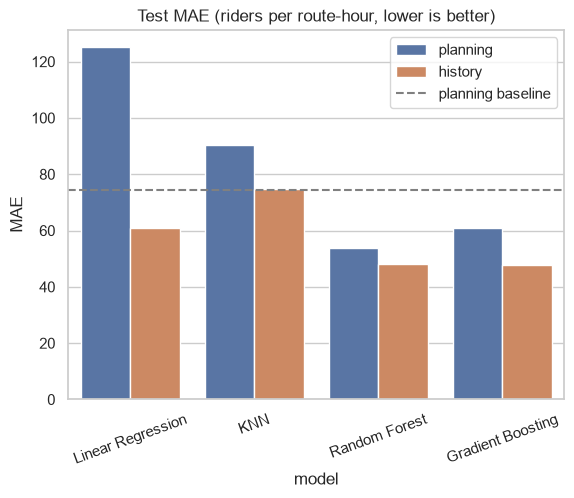

In [11]:
plot_data = test_table[test_table["model"] != "Baseline"]
sns.barplot(data=plot_data, x="model", y="MAE", hue="variant")
plt.axhline(test_table.query("variant == 'planning' and model == 'Baseline'")["MAE"].iloc[0], color="grey", linestyle="--", label="planning baseline")
plt.xticks(rotation=20)
plt.title("Test MAE (riders per route-hour, lower is better)")
plt.legend()
plt.savefig("../figures/08_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Error analysis of the chosen models

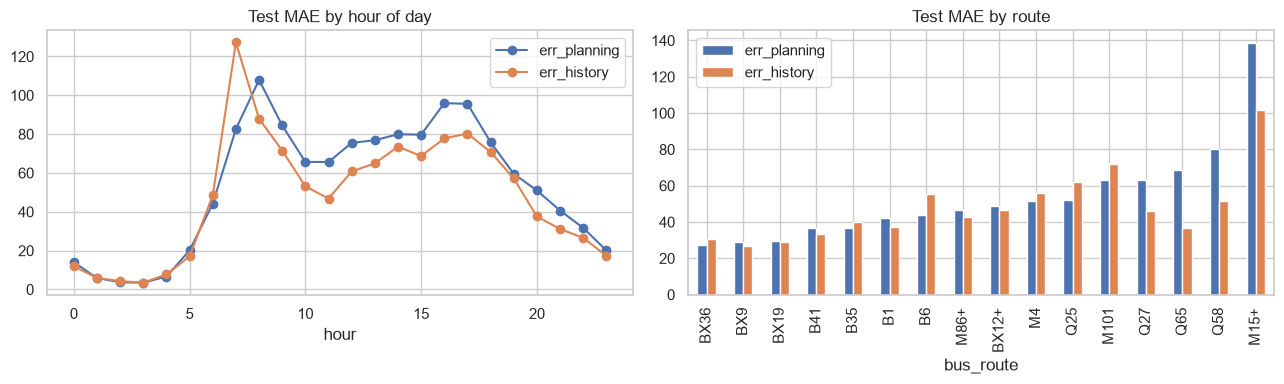

In [12]:
chosen = {v: final_models[(v, best_name[v])] for v in variants}
analysis = test[["transit_timestamp", "bus_route", "hour", "is_weekend", target]].copy()
for v in variants:
    analysis[f"pred_{v}"] = chosen[v].predict(test[variants[v]])
    analysis[f"err_{v}"] = (analysis[target] - analysis[f"pred_{v}"]).abs()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_hour = analysis.groupby("hour")[["err_planning", "err_history"]].mean()
by_hour.plot(ax=ax[0], marker="o")
ax[0].set_title("Test MAE by hour of day")
by_route = analysis.groupby("bus_route")[["err_planning", "err_history"]].mean().sort_values("err_planning")
by_route.plot.bar(ax=ax[1])
ax[1].set_title("Test MAE by route")
plt.tight_layout()
plt.savefig("../figures/09_error_by_hour_route.png", dpi=150)
plt.show()

**Errors by hour:** the biggest errors are at the morning rush (7-8 am) and the afternoon peak. Overnight errors are tiny because ridership itself is tiny. The history model's worst hour is 7 am: ridership jumps suddenly, and the lag features from 6 am still say 'quiet'.

**Errors by route:** errors grow with route size, so M15+ (the busiest) has the biggest error. In percent of the route's average ridership, errors are mostly 8-15%, with M15+ and Q65 around 20% for the planning model.

**Actual vs predicted (M15+):** both models follow the daily shape and the weekday/weekend difference well. The planning model overshoots the weekday afternoon peak (it predicts about 2,000, actual is 1,200-1,700). Part of the reason is that M15+'s September afternoon peak (about 1,680 riders at 4-5 pm) is 6-12% lower than in the other windows (1,790-1,910), but that does not fully explain the gap. The planning model has no recent ridership to notice the change, which is exactly what the history model can do.

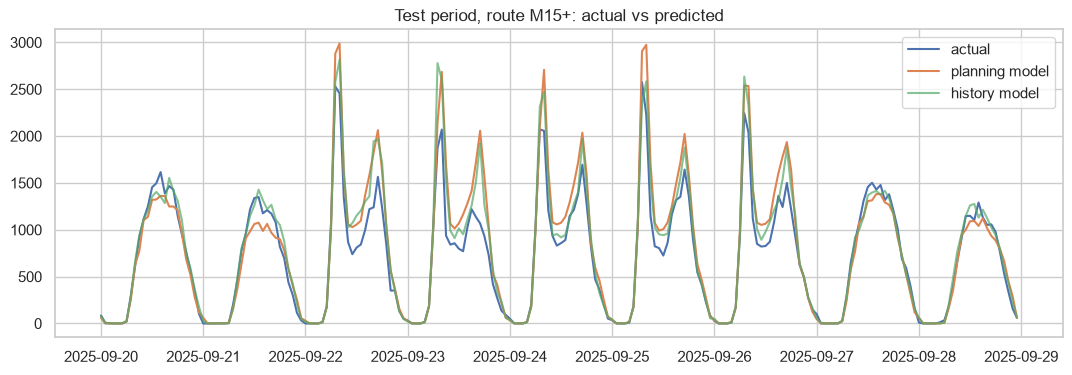

In [13]:
route = analysis.groupby("bus_route")[target].mean().idxmax()
one = analysis[analysis["bus_route"] == route]
plt.figure(figsize=(13, 4))
plt.plot(one["transit_timestamp"], one[target], label="actual")
plt.plot(one["transit_timestamp"], one["pred_planning"], label="planning model")
plt.plot(one["transit_timestamp"], one["pred_history"], label="history model", alpha=0.7)
plt.title(f"Test period, route {route}: actual vs predicted")
plt.legend()
plt.savefig("../figures/10_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

**Actual vs predicted (M15+):** both models follow the daily shape and the weekday/weekend difference well. The planning model overshoots the weekday afternoon peak (it predicts about 2,000, actual is 1,200-1,700). Part of the reason is that M15+'s September afternoon peak (about 1,680 riders at 4-5 pm) is 6-12% lower than in the other windows (1,790-1,910), but that does not fully explain the gap. The planning model has no recent ridership to notice the change, which is exactly what the history model can do.

## 10. Save the final pipelines

In [14]:
import os
os.makedirs("../models", exist_ok=True)
for v in variants:
    joblib.dump(chosen[v], f"../models/{v}_model.joblib")
    print(v, "->", best_name[v])

planning -> Random Forest


history -> Random Forest


## Summary of findings
- Tree ensembles (Random Forest, Gradient Boosting) clearly beat the baselines, KNN and Linear Regression.
- **Planning model (no history): MAE 53.6, R2 0.94, vs baseline 74.5. History model: MAE 48.0, R2 0.95, vs baseline 66.0.**
- History features help only a little (about 10% lower error). The history model is better on 10 of 16 routes and mainly on weekends (MAE 33 vs 44); on weekdays the two models are almost tied (60 vs 61). So the planning model, which needs no recent data, is good enough for the app.
- The test set is only 9 days at the end of September, so small differences between models (like 48.0 vs 47.7) are not meaningful.
- The planning model was tested with **actual** weather, not a forecast. The app will use forecasts or typical weather, so real-life error will be somewhat higher.
- Everything comes from four 2-week windows in 2025 and one city, so results do not prove the model works for other seasons or cities.